# 30. C 시드 평균 OOF: 신장(KIPAN·KIRC)·뇌(GBMLGG·LGG) 그룹 밖 예측 비율

## 배경
- 라벨에는 묶음 코호트와 하위 코호트가 같이 있음 (FAM110B 논문의 TCGA 명명: KIPAN = KICH + KIRC + KIRP, GBMLGG = GBM + LGG)
  - 이 데이터에서는 **신장 그룹 = KIPAN, KIRC**, **뇌 그룹 = GBMLGG, LGG**
- 같은 그룹 안의 혼동(KIRC ↔ KIPAN)은 라벨 정의상 피하기 어렵지만, **그룹 밖으로 틀리는 것**(예: KIRC → LUAD)은 모델이 장기 자체를 놓친 것
- LB 최고 계열인 C 시드 평균(22b XGB 시드 5개 0.7 + LR 0.3, 데스크탑 LB 0.3660)의 OOF에서 두 경우를 나눠 봄

## 확인할 것
1. KIRC·KIPAN·LGG·GBMLGG 환자 각각: 정답 / 그룹 안 다른 클래스 / **그룹 밖** 비율, 그룹 밖으로 간 상위 클래스
2. 네 클래스의 혼동행렬 (행 = 실제, 열 = 예측, 나머지 클래스는 "그룹 밖"으로 묶음)
3. 참고: 시드 42 C와 비교, 다른 클래스 전체의 오답 비율

## 방법
- C 시드 평균은 23·25·26 노트북과 같은 방식: 22b XGB(10 설정) 시드 42, 0, 1, 2, 3 확률 평균 × 0.7 + LR(any, C=0.1, balanced) × 0.3, fold(seed 42) 고정
- OOF(검증 fold 예측)만 사용 → 진단용 분석, 모델·피처·후처리는 바꾸지 않음
  - 팀 결정: 묶음 라벨을 이용한 후처리(KIPAN↔KIRC 보정)는 하지 않음 → 이 노트북은 해석·발표용
- 실행 환경: macOS M1 (데스크탑과 XGB 확률이 조금 다를 수 있음)

#### 준비: 데이터, 22b 피처, C 시드 평균 OOF
- 시간이 걸림 (XGB 5개 + LR, 약 20분)

In [1]:
import sys; sys.path.append('..')
import time, platform, numpy as np, pandas as pd, xgboost as xgb
from collections import Counter
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.utils.class_weight import compute_sample_weight
from src.config import SEED, WT
from src.data import load_data, get_gene_cols
from src.features import mutation_features, mutation_type, aa_substitution
from src.validation import seed_everything, encode_target, get_folds, run_cv, macro_f1

print(f'{platform.system()} | CPU {platform.machine()} | xgboost {xgb.__version__}')
seed_everything()
train, test, submission = load_data()
genes = get_gene_cols(train)
y, le = encode_target(train)
folds = get_folds(y)
F_tr, F_te = mutation_features(train, genes), mutation_features(test, genes)

class BalancedXGB(xgb.XGBClassifier):
    def fit(self, X, y, **kw):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y), **kw)

BEST = dict(max_depth=3, learning_rate=0.1, n_estimators=200, colsample_bytree=0.3,
            tree_method='hist', eval_metric='mlogloss', random_state=SEED, n_jobs=-1)

def sub_ratio_matrix(df):
    rows = []
    for row in df[genes].to_numpy():
        subs = (aa_substitution(t) for v in row if v != WT for t in v.split() if mutation_type(t) == 'missense')
        c = Counter(s for s in subs if s is not None)
        tot = sum(c.values())
        rows.append({k: n / tot for k, n in c.items()} if tot else {})
    M = pd.DataFrame(rows, index=df.index).fillna(0).astype(np.float32)
    M.columns = ['sub__' + k.replace('>', '_') for k in M.columns]
    return M

class TopNSubs(BaseEstimator, TransformerMixin):
    def __init__(self, n=100):
        self.n = n
    def fit(self, X, y=None):
        sub = [c for c in X.columns if c.startswith('sub__')]
        keep = set(X[sub].sum().sort_values(ascending=False).index[:self.n])
        self.drop_ = [c for c in sub if c not in keep]
        return self
    def transform(self, X):
        return X.drop(columns=self.drop_)

S_tr = sub_ratio_matrix(train)
S_te = sub_ratio_matrix(test).reindex(columns=S_tr.columns, fill_value=0)
X22b, X22b_te = pd.concat([F_tr['any'], F_tr['ratio'], S_tr], axis=1), pd.concat([F_te['any'], F_te['ratio'], S_te], axis=1)

SEEDS = [42, 0, 1, 2, 3]
xgb_oof, xgb_te = {}, {}
for s in SEEDS:
    t = time.time()
    params = {**BEST, 'random_state': s}
    r = run_cv(lambda: make_pipeline(TopNSubs(100), BalancedXGB(**params)), X22b, y, X22b_te, folds=folds, verbose=False)
    xgb_oof[s], xgb_te[s] = r['oof_proba'], r['test_proba']
    print(f"22b XGB 시드 {s}: CV {r['cv_mean']:.4f} ({time.time() - t:.0f}s)")
r_lr = run_cv(lambda: LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced', random_state=SEED),
              F_tr['any'].astype('float32'), y, F_te['any'].astype('float32'), folds=folds, verbose=False)

P = {'C 시드 평균': 0.7 * np.mean([xgb_oof[s] for s in SEEDS], axis=0) + 0.3 * r_lr['oof_proba'],
     'C (시드 42)': 0.7 * xgb_oof[42] + 0.3 * r_lr['oof_proba']}
PT = {'C 시드 평균': 0.7 * np.mean([xgb_te[s] for s in SEEDS], axis=0) + 0.3 * r_lr['test_proba'],
      'C (시드 42)': 0.7 * xgb_te[42] + 0.3 * r_lr['test_proba']}
for k, po in P.items():
    fs = [macro_f1(y[va], po[va].argmax(1)) for _, va in folds]
    print(f"{k}: CV {np.mean(fs):.4f} ± {np.std(fs):.4f}, OOF {macro_f1(y, po.argmax(1)):.4f}")

Darwin | CPU arm64 | xgboost 3.4.1


22b XGB 시드 42: CV 0.4487 (175s)


22b XGB 시드 0: CV 0.4507 (184s)


22b XGB 시드 1: CV 0.4566 (185s)


22b XGB 시드 2: CV 0.4534 (195s)


22b XGB 시드 3: CV 0.4546 (180s)


C 시드 평균: CV 0.4622 ± 0.0082, OOF 0.4631
C (시드 42): CV 0.4557 ± 0.0065, OOF 0.4565


#### 1) 클래스별: 정답 / 그룹 안 / 그룹 밖 (C 시드 평균 OOF)
- 그룹 밖 = 같은 장기 그룹이 아닌 클래스로 예측된 비율

In [2]:
GROUP = {'KIRC': 'kidney', 'KIPAN': 'kidney', 'LGG': 'brain', 'GBMLGG': 'brain'}
TARGETS = ['KIRC', 'KIPAN', 'LGG', 'GBMLGG']
true_lab = le.classes_[y]

def group_table(po):
    pred_lab = le.classes_[po.argmax(1)]
    rows = []
    for c in TARGETS:
        m = true_lab == c
        p = pred_lab[m]
        same = p == c
        in_grp = np.array([GROUP.get(x) == GROUP[c] for x in p]) & ~same
        out = ~(same | in_grp)
        top_out = Counter(p[out]).most_common(3)
        rows.append({'실제': c, '환자 수': int(m.sum()), '정답': f'{same.mean():.1%}',
                     '그룹 안 다른 클래스': f'{in_grp.mean():.1%}', '그룹 밖': f'{out.mean():.1%}',
                     '그룹 밖 상위 예측': ', '.join(f'{k} {v}명' for k, v in top_out)})
    return pd.DataFrame(rows)

group_table(P['C 시드 평균'])

,실제,환자 수,정답,그룹 안 다른 클래스,그룹 밖,그룹 밖 상위 예측
0,KIRC,334,19.5%,53.3%,27.2%,"PRAD 27명, PCPG 10명, TGCT 9명"
1,KIPAN,515,19.2%,44.5%,36.3%,"PRAD 38명, LIHC 24명, TGCT 20명"
2,LGG,229,62.0%,27.5%,10.5%,"SARC 4명, LAML 4명, THYM 3명"
3,GBMLGG,461,25.6%,43.6%,30.8%,"PAAD 17명, CESC 13명, BRCA 13명"


#### 2) 혼동행렬 (C 시드 평균 OOF, 행 = 실제, 열 = 예측)
- 네 클래스 밖의 예측은 "그룹 밖(기타)" 한 열로 묶음, 아래 표는 환자 수와 행 비율

In [3]:
pred_lab = le.classes_[P['C 시드 평균'].argmax(1)]
cols = TARGETS + ['그룹 밖(기타)']
cm = pd.DataFrame(0, index=TARGETS, columns=cols)
for c in TARGETS:
    for p in pred_lab[true_lab == c]:
        cm.loc[c, p if p in TARGETS else '그룹 밖(기타)'] += 1
pct = cm.div(cm.sum(axis=1), axis=0).mul(100).round(1)
pd.concat({'환자 수': cm, '행 비율 (%)': pct}, axis=1)

환자 수                            행 비율 (%)                            
       KIRC KIPAN  LGG GBMLGG 그룹 밖(기타)     KIRC KIPAN   LGG GBMLGG 그룹 밖(기타)
KIRC     65   178    0      5       86     19.5  53.3   0.0    1.5     25.7
KIPAN   229    99    0      6      181     44.5  19.2   0.0    1.2     35.1
LGG       0     1  142     63       23      0.0   0.4  62.0   27.5     10.0
GBMLGG    6     8  201    118      128      1.3   1.7  43.6   25.6     27.8

#### 3) 참고: 그룹 단위 요약, 시드 42와 비교, 다른 클래스 오답 비율

In [4]:
def summary(po):
    pred = le.classes_[po.argmax(1)]
    out = {}
    for g, members in [('신장 (KIPAN·KIRC)', ['KIPAN', 'KIRC']), ('뇌 (GBMLGG·LGG)', ['GBMLGG', 'LGG'])]:
        m = np.isin(true_lab, members)
        out[f'{g} 그룹 밖'] = f'{(~np.isin(pred[m], members)).mean():.1%}'
        out[f'{g} 그룹 안 혼동'] = f'{(np.isin(pred[m], members) & (pred[m] != true_lab[m])).mean():.1%}'
    others = ~np.isin(true_lab, TARGETS)
    out['나머지 22개 클래스 오답'] = f'{(pred[others] != true_lab[others]).mean():.1%}'
    return out

pd.DataFrame({k: summary(po) for k, po in P.items()})

,C 시드 평균,C (시드 42)
신장 (KIPAN·KIRC) 그룹 밖,32.7%,32.7%
신장 (KIPAN·KIRC) 그룹 안 혼동,47.9%,49.0%
뇌 (GBMLGG·LGG) 그룹 밖,24.1%,24.6%
뇌 (GBMLGG·LGG) 그룹 안 혼동,38.3%,38.4%
나머지 22개 클래스 오답,49.5%,50.0%


#### 그래프: 정답 / 그룹 안 / 그룹 밖 (C 시드 평균 OOF)
- 클래스마다 환자 전체를 100%로 두고 세 부분으로 나눔, 오른쪽은 그룹 밖 상위 예측
- PNG는 `outputs/presentation_eunji/nb30_group_confusion.png`에도 저장 (git 제외 폴더)

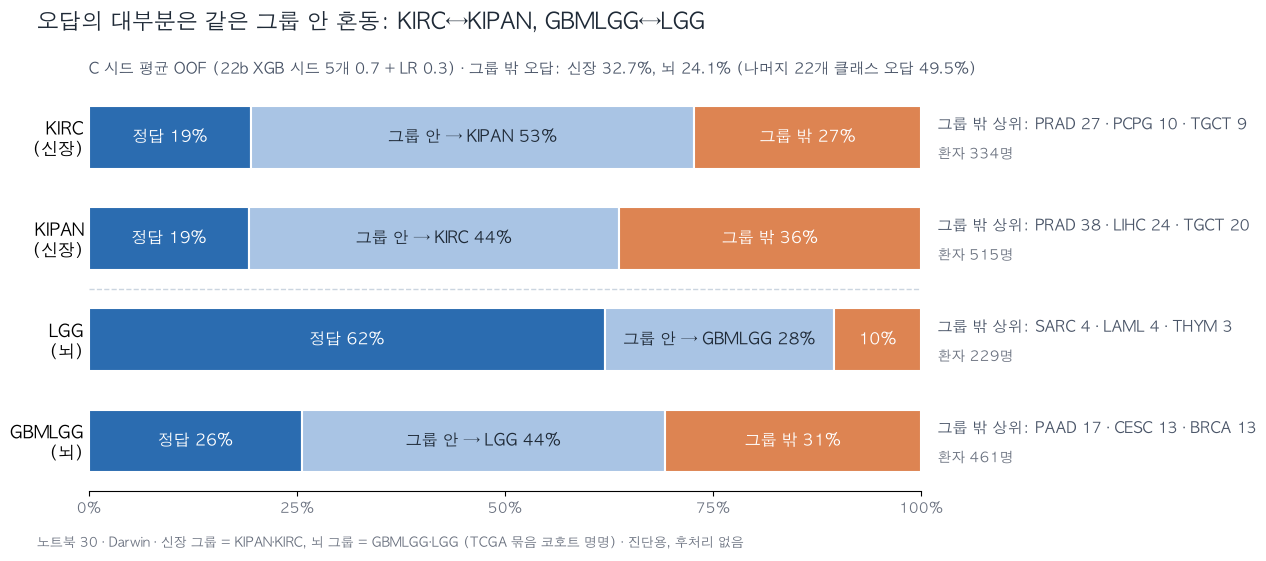

In [5]:
import os
import matplotlib.pyplot as plt
from matplotlib import font_manager

for f in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = f
        break
plt.rcParams['axes.unicode_minus'] = False
C_OK, C_IN, C_OUT = '#2b6cb0', '#a9c4e4', '#dd8452'
NAME = {'kidney': '신장', 'brain': '뇌'}
PARTNER = {'KIRC': 'KIPAN', 'KIPAN': 'KIRC', 'LGG': 'GBMLGG', 'GBMLGG': 'LGG'}

pred_lab = le.classes_[P['C 시드 평균'].argmax(1)]
fig, ax = plt.subplots(figsize=(13, 5.6))
ys = list(range(len(TARGETS)))[::-1]
for y_pos, c in zip(ys, TARGETS):
    p = pred_lab[true_lab == c]
    n = len(p)
    ok = int((p == c).sum())
    inn = int(sum(GROUP.get(x) == GROUP[c] and x != c for x in p))
    out = n - ok - inn
    top = Counter(x for x in p if GROUP.get(x) != GROUP[c]).most_common(3)
    left = 0
    for w, col, lab, tc in [(ok / n, C_OK, f'정답 {ok / n:.0%}', 'white'),
                            (inn / n, C_IN, f'그룹 안 → {PARTNER[c]} {inn / n:.0%}', '#1f2a37'),
                            (out / n, C_OUT, f'그룹 밖 {out / n:.0%}', 'white')]:
        ax.barh(y_pos, w, left=left, color=col, height=0.62, edgecolor='white', linewidth=1.5)
        ax.text(left + w / 2, y_pos, lab if w >= 0.14 else lab.split()[-1], ha='center', va='center', fontsize=11.5, color=tc)
        left += w
    ax.text(1.02, y_pos + 0.12, '그룹 밖 상위: ' + ' · '.join(f'{k} {v}' for k, v in top), va='center', fontsize=10.5, color='#4a5568')
    ax.text(1.02, y_pos - 0.17, f'환자 {n}명', va='center', fontsize=10, color='#6b7280')

s = summary(P['C 시드 평균'])
ax.set_yticks(ys, [f'{c}\n({NAME[GROUP[c]]})' for c in TARGETS], fontsize=12)
ax.set_xlim(0, 1)
ax.set_xticks([0, .25, .5, .75, 1], ['0%', '25%', '50%', '75%', '100%'], fontsize=10, color='#6b7280')
ax.axhline(1.5, color='#cbd5e0', lw=1, ls='--')
for sp in ['top', 'right', 'left']:
    ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', length=0)
fig.suptitle('오답의 대부분은 같은 그룹 안 혼동: KIRC↔KIPAN, GBMLGG↔LGG', x=0.06, ha='left', fontsize=16, color='#1f2a37')
ax.set_title(f"C 시드 평균 OOF (22b XGB 시드 5개 0.7 + LR 0.3) · 그룹 밖 오답: 신장 {s['신장 (KIPAN·KIRC) 그룹 밖']}, "
             f"뇌 {s['뇌 (GBMLGG·LGG) 그룹 밖']} (나머지 22개 클래스 오답 {s['나머지 22개 클래스 오답']})",
             loc='left', fontsize=11, color='#4a5568', pad=10)
fig.text(0.06, 0.02, f'노트북 30 · {platform.system()} · 신장 그룹 = KIPAN·KIRC, 뇌 그룹 = GBMLGG·LGG (TCGA 묶음 코호트 명명) · 진단용, 후처리 없음',
         fontsize=9.5, color='#6b7280')
fig.subplots_adjust(left=0.1, right=0.74, top=0.84, bottom=0.12)
os.makedirs('../outputs/presentation_eunji', exist_ok=True)
fig.savefig('../outputs/presentation_eunji/nb30_group_confusion.png', dpi=200)
plt.show()

#### 4) 참고: test 예측 비율 (관찰용, 판단 기준 아님)

In [6]:
tr_share = pd.Series(true_lab).value_counts(normalize=True)
pd.DataFrame({'train 비율': tr_share.reindex(TARGETS),
              **{f'test 예측 ({k})': pd.Series(le.classes_[pt.argmax(1)]).value_counts(normalize=True).reindex(TARGETS)
                 for k, pt in PT.items()}}).fillna(0).mul(100).round(1).astype(str) + '%'

,train 비율,test 예측 (C 시드 평균),test 예측 (C (시드 42))
KIRC,5.4%,3.9%,3.9%
KIPAN,8.3%,5.7%,5.6%
LGG,3.7%,3.5%,3.3%
GBMLGG,7.4%,2.9%,2.9%


## 결과 (macOS M1, C 시드 평균 CV 0.4622 ± 0.0082, OOF 0.4631)

**1) 클래스별 (C 시드 평균 OOF)**

| 실제 | 환자 수 | 정답 | 그룹 안 다른 클래스 | **그룹 밖** | 그룹 밖 상위 예측 |
| :--- | :-: | :-: | :-: | :-: | :--- |
| KIRC | 334 | 19.5% | 53.3% (→ KIPAN) | **27.2%** | PRAD 27, PCPG 10, TGCT 9 |
| KIPAN | 515 | 19.2% | 44.5% (→ KIRC) | **36.3%** | PRAD 38, LIHC 24, TGCT 20 |
| LGG | 229 | 62.0% | 27.5% (→ GBMLGG) | **10.5%** | SARC 4, LAML 4, THYM 3 |
| GBMLGG | 461 | 25.6% | 43.6% (→ LGG) | **30.8%** | PAAD 17, CESC 13, BRCA 13 |

**2) 혼동행렬 (행 = 실제, 열 = 예측, 환자 수)**

| 실제 \ 예측 | KIRC | KIPAN | LGG | GBMLGG | 그룹 밖(기타) |
| :--- | :-: | :-: | :-: | :-: | :-: |
| KIRC | 65 | **178** | 0 | 5 | 86 |
| KIPAN | **229** | 99 | 0 | 6 | 181 |
| LGG | 0 | 1 | 142 | 63 | 23 |
| GBMLGG | 6 | 8 | **201** | 118 | 128 |

**3) 그룹 단위 요약**

| | C 시드 평균 | C (시드 42) |
| :--- | :-: | :-: |
| 신장(KIPAN·KIRC) 그룹 밖 | 32.7% | 32.7% |
| 신장 그룹 안 혼동 | 47.9% | 49.0% |
| 뇌(GBMLGG·LGG) 그룹 밖 | 24.1% | 24.6% |
| 뇌 그룹 안 혼동 | 38.3% | 38.4% |
| 나머지 22개 클래스 오답 | 49.5% | 50.0% |

**해석**
- **그룹 안 혼동이 가장 큼**: KIRC의 53%가 KIPAN으로, KIPAN의 45%가 KIRC로 예측됨 → 정답률이 19%대로 낮은 주된 이유는 장기를 못 맞힌 게 아니라 묶음/하위 라벨을 못 가르는 것
  - KIPAN에는 KIRC 환자도 포함되는 라벨 정의라 변이 프로필만으로는 구분이 어려움 (05에서 본 같은 프로필·다른 라벨)
  - 뇌도 같은 패턴: GBMLGG의 44%가 LGG로 예측, 반대로 LGG는 정답 62%로 상대적으로 잘 맞힘
- **그룹 밖 오답**: 신장 32.7%, 뇌 24.1% → 나머지 22개 클래스 오답(49.5%)보다는 낮음 → 장기 자체는 비교적 잘 잡음
  - 신장이 그룹 밖으로 갈 때는 **PRAD**(신장·전립선 모두 비뇨기), LIHC, TGCT, PCPG가 많음
  - GBMLGG가 그룹 밖으로 갈 때는 PAAD, CESC, BRCA처럼 특정 장기 쪽으로 몰리지 않고 흩어짐
- 시드 평균은 그룹 안 혼동을 조금 줄였지만(신장 49.0% → 47.9%), 그룹 밖 비율은 거의 같음
- test 예측 (관찰용): GBMLGG 2.9%(train 7.4%), KIPAN 5.7%(8.3%), KIRC 3.9%(5.4%)로 train보다 적게 예측

## 결론
- C 시드 평균에서 네 클래스의 오답은 **대부분 같은 그룹 안의 혼동**(신장 47.9%, 뇌 38.3%)이고, 그룹 밖 오답(신장 32.7%, 뇌 24.1%)은 다른 클래스 평균 오답(49.5%)보다 낮음
- 즉 모델은 "신장인지, 뇌인지"는 비교적 잘 맞히고, "묶음 라벨(KIPAN·GBMLGG)인지 하위 라벨(KIRC·LGG)인지"를 못 가름 → 변이 데이터만으로는 구분 정보가 부족한 부분 (라벨 정의의 한계)
- 팀 결정대로 묶음 라벨 후처리는 하지 않음 → 이 결과는 발표에서 "오답의 성격" 설명용으로 사용
- 그룹 밖 오답 중 신장 → PRAD(65명)는 비뇨기 계통끼리의 혼동이라 발표에서 같이 언급할 만함
